<center> <img src = https://raw.githubusercontent.com/AndreyRysistov/DatasetsForPandas/main/hh%20label.jpg alt="drawing" style="width:400px;">

# Проект: Анализ резюме из HeadHunter

Цель — исследовать структуру резюме, преобразовать признаки, изучить связи с желаемой зарплатой и очистить данные. Зарплаты в проекте отражают ожидания соискателей, а не фактические доходы.

**Источники данных:** [исходный датасет HeadHunter](https://drive.google.com/file/d/1Kb78mAWYKcYlellTGhIjPI-bCcKbGuTn/view?usp=sharing) и [архив курсов валют из курса](https://lms-cdn.skillfactory.ru/assets/courseware/v1/15abf80f45a2f3e93c3274101b451c67/asset-v1:skillfactory+MIFIML-1sem+2026+type@asset+block/ExchangeRates.zip).

Для запуска положите файл **dst-3.0_16_1_hh_database.csv** рядом с ноутбуком (в Colab — загрузите в файлы сеанса) и выполните все ячейки сверху вниз. Курсы валют загружаются по ссылке автоматически; для этой ячейки требуется интернет. Данные не включены в ноутбук из-за размера. Используются pandas, NumPy, Matplotlib и Seaborn; статические графики сохраняются в выводах ноутбука.

Исходная таблица содержит **44 744 строки и 12 столбцов**. После преобразований и последовательной очистки итоговая таблица **hh_clean** содержит **44 482 строки и 23 признака**. Ниже сохранены код, результаты вычислений и выводы к каждому графику.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Исследование структуры данных

1. Прочитайте данные с помощью библиотеки Pandas. Совет: перед чтением обратите внимание на разделитель внутри файла.

In [ ]:
hh_data = pd.read_csv('dst-3.0_16_1_hh_database.csv', sep=';')
hh_data.shape

(44744, 12)

2. Выведите несколько первых (последних) строк таблицы, чтобы убедиться в том, что ваши данные не повреждены. Ознакомьтесь с признаками и их структурой.

In [ ]:
hh_data.head()

,"Пол, возраст",ЗП,Ищет работу на должность:,"Город, переезд, командировки",Занятость,График,Опыт работы,Последнее/нынешнее место работы,Последняя/нынешняя должность,Образование и ВУЗ,Обновление резюме,Авто
0,"Мужчина , 39 лет , родился 27 ноября 1979",29000 руб.,Системный администратор,"Советск (Калининградская область) , не готов к...","частичная занятость, проектная работа, полная ...","гибкий график, полный день, сменный график, ва...",Опыт работы 16 лет 10 месяцев Август 2010 — п...,"МАОУ ""СОШ № 1 г.Немана""",Системный администратор,Неоконченное высшее образование 2000 Балтийск...,16.04.2019 15:59,Имеется собственный автомобиль
1,"Мужчина , 60 лет , родился 20 марта 1959",40000 руб.,Технический писатель,"Королев , не готов к переезду , готов к редким...","частичная занятость, проектная работа, полная ...","гибкий график, полный день, сменный график, уд...",Опыт работы 19 лет 5 месяцев Январь 2000 — по...,Временный трудовой коллектив,"Менеджер проекта, Аналитик, Технический писатель",Высшее образование 1981 Военно-космическая ак...,12.04.2019 08:42,Не указано
2,"Женщина , 36 лет , родилась 12 августа 1982",20000 руб.,Оператор,"Тверь , не готова к переезду , не готова к ком...",полная занятость,полный день,Опыт работы 10 лет 3 месяца Октябрь 2004 — Де...,ПАО Сбербанк,Кассир-операционист,Среднее специальное образование 2002 Профессио...,16.04.2019 08:35,Не указано
3,"Мужчина , 38 лет , родился 25 июня 1980",100000 руб.,Веб-разработчик (HTML / CSS / JS / PHP / базы ...,"Саратов , не готов к переезду , готов к редким...","частичная занятость, проектная работа, полная ...","гибкий график, удаленная работа",Опыт работы 18 лет 9 месяцев Август 2017 — Ап...,OpenSoft,Инженер-программист,Высшее образование 2002 Саратовский государст...,08.04.2019 14:23,Не указано
4,"Женщина , 26 лет , родилась 3 марта 1993",140000 руб.,Региональный менеджер по продажам,"Москва , не готова к переезду , готова к коман...",полная занятость,полный день,Опыт работы 5 лет 7 месяцев Региональный мене...,Мармелад,Менеджер по продажам,Высшее образование 2015 Кгу Психологии и педаг...,22.04.2019 10:32,Не указано


3. Выведите основную информацию о числе непустых значений в столбцах и их типах в таблице.

4. Обратите внимание на информацию о числе непустых значений.

In [ ]:
hh_data.info()
print('\nПропуски по столбцам:')
print(hh_data.isna().sum().to_string())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44744 entries, 0 to 44743
Data columns (total 12 columns):
 #   Column                           Non-Null Count  Dtype 
---  ------                           --------------  ----- 
 0   Пол, возраст                     44744 non-null  object
 1   ЗП                               44744 non-null  object
 2   Ищет работу на должность:        44744 non-null  object
 3   Город, переезд, командировки     44744 non-null  object
 4   Занятость                        44744 non-null  object
 5   График                           44744 non-null  object
 6   Опыт работы                      44576 non-null  object
 7   Последнее/нынешнее место работы  44743 non-null  object
 8   Последняя/нынешняя должность     44742 non-null  object
 9   Образование и ВУЗ                44744 non-null  object
 10  Обновление резюме                44744 non-null  object
 11  Авто                             44744 non-null  object
dtypes: object(12)
memory usage: 4.1+

5. Выведите основную статистическую информацию о столбцах.


In [ ]:
display(hh_data.describe(include='object').T)
print('Уникальных вариантов опыта:', hh_data['Опыт работы'].nunique())
print('Самая популярная должность:', hh_data['Ищет работу на должность:'].mode().iloc[0])

,count,unique,top,freq
"Пол, возраст",44744,16003,"Мужчина , 32 года , родился 17 сентября 1986",18
ЗП,44744,690,50000 руб.,4064
Ищет работу на должность:,44744,14929,Системный администратор,3099
"Город, переезд, командировки",44744,10063,"Москва , не готов к переезду , не готов к кома...",1261
Занятость,44744,38,полная занятость,30026
График,44744,47,полный день,22727
Опыт работы,44576,44413,Опыт работы 10 лет 8 месяцев Апрель 2018 — по...,3
Последнее/нынешнее место работы,44743,30214,Индивидуальное предпринимательство / частная п...,935
Последняя/нынешняя должность,44742,16927,Системный администратор,2062
Образование и ВУЗ,44744,40148,Высшее образование 2014 Тюменский Государствен...,4


Уникальных вариантов опыта: 44413
Самая популярная должность: Системный администратор


# Преобразование данных

1. Начнем с простого - с признака **"Образование и ВУЗ"**. Его текущий формат это: **<Уровень образования год выпуска ВУЗ специальность...>**. Например:
* Высшее образование 2016 Московский авиационный институт (национальный исследовательский университет)...
* Неоконченное высшее образование 2000  Балтийская государственная академия рыбопромыслового флота…
Нас будет интересовать только уровень образования.

Создайте с помощью функции-преобразования новый признак **"Образование"**, который должен иметь 4 категории: "высшее", "неоконченное высшее", "среднее специальное" и "среднее".

Выполните преобразование, ответьте на контрольные вопросы и удалите признак "Образование и ВУЗ".

Совет: обратите внимание на структуру текста в столбце **"Образование и ВУЗ"**. Гарантируется, что текущий уровень образования соискателя всегда находится в первых 2ух слов и начинается с заглавной буквы. Воспользуйтесь этим.

*Совет: проверяйте полученные категории, например, с помощью метода unique()*


In [ ]:
# Сохраняем исходную таблицу, чтобы преобразования можно было повторить.
hh_raw = hh_data.copy()

def get_education(value):
    words = value.lower().split()
    if words[0] == 'высшее':
        return 'высшее'
    if words[:2] == ['неоконченное', 'высшее']:
        return 'неоконченное высшее'
    if words[:2] == ['среднее', 'специальное']:
        return 'среднее специальное'
    return 'среднее'

hh_data['Образование'] = hh_data['Образование и ВУЗ'].apply(get_education)
print(hh_data['Образование'].value_counts().to_string())
hh_data = hh_data.drop(columns='Образование и ВУЗ')

Образование
высшее                 33863
среднее специальное     5765
неоконченное высшее     4557
среднее                  559


2. Теперь нас интересует столбец **"Пол, возраст"**. Сейчас он представлен в формате **<Пол , возраст , дата рождения >**. Например:
* Мужчина , 39 лет , родился 27 ноября 1979
* Женщина , 21 год , родилась 13 января 2000
Как вы понимаете, нам необходимо выделить каждый параметр в отдельный столбец.

Создайте два новых признака **"Пол"** и **"Возраст"**. При этом важно учесть:
* Признак пола должен иметь 2 уникальных строковых значения: 'М' - мужчина, 'Ж' - женщина.
* Признак возраста должен быть представлен целыми числами.

Выполните преобразование, ответьте на контрольные вопросы и удалите признак **"Пол, возраст"** из таблицы.

*Совет: обратите внимание на структуру текста в столбце, в части на то, как разделены параметры пола, возраста и даты рождения между собой - символом ' , '.
Гарантируется, что структура одинакова для всех строк в таблице. Вы можете воспользоваться этим.*


In [ ]:
def get_gender(value):
    return value.split(',')[0].strip()[0]

def get_age(value):
    return int(value.split(',')[1].strip().split()[0])

hh_data['Пол'] = hh_data['Пол, возраст'].apply(get_gender)
hh_data['Возраст'] = hh_data['Пол, возраст'].apply(get_age)
print('Доля женских резюме, %:', round(hh_data['Пол'].eq('Ж').mean() * 100, 2))
print('Средний возраст:', round(hh_data['Возраст'].mean(), 1))
print('Категории пола:', hh_data['Пол'].unique())
hh_data = hh_data.drop(columns='Пол, возраст')

Доля женских резюме, %: 19.07
Средний возраст: 32.2
Категории пола: ['М' 'Ж']


3. Следующим этапом преобразуем признак **"Опыт работы"**. Его текущий формат - это: **<Опыт работы: n лет m месяцев, периоды работы в различных компаниях…>**.

Из столбца нам необходимо выделить общий опыт работы соискателя в месяцах, новый признак назовем "Опыт работы (месяц)"

Для начала обсудим условия решения задачи:
* Во-первых, в данном признаке есть пропуски. Условимся, что если мы встречаем пропуск, оставляем его как есть (функция-преобразование возвращает NaN)
* Во-вторых, в данном признаке есть скрытые пропуски. Для некоторых соискателей в столбце стоит значения "Не указано". Их тоже обозначим как NaN (функция-преобразование возвращает NaN)
* В-третьих, нас не интересует информация, которая описывается после указания опыта работы (периоды работы в различных компаниях)
* В-четвертых, у нас есть проблема: опыт работы может быть представлен только в годах или только месяцах. Например, можно встретить следующие варианты:
    * Опыт работы 3 года 2 месяца…
    * Опыт работы 4 года…
    * Опыт работы 11 месяцев…
    * Учитывайте эту особенность в вашем коде

Учитывайте эту особенность в вашем коде

В результате преобразования у вас должен получиться столбец, содержащий информацию о том, сколько месяцев проработал соискатель.
Выполните преобразование, ответьте на контрольные вопросы и удалите столбец **"Опыт работы"** из таблицы.


In [ ]:
def get_experience(value):
    if pd.isna(value) or value.strip() == 'Не указано':
        return np.nan
    # Общая продолжительность указана в начале, до истории мест работы.
    words = value.split()[2:6]
    months = 0
    found = False
    for i in range(1, len(words)):
        if words[i - 1].isdigit():
            if words[i] in ['год', 'года', 'лет']:
                months += int(words[i - 1]) * 12
                found = True
            elif words[i] in ['месяц', 'месяца', 'месяцев']:
                months += int(words[i - 1])
                found = True
    return months if found else np.nan

hh_data['Опыт работы (месяц)'] = hh_data['Опыт работы'].apply(get_experience)
print('Медианный опыт, месяцев:', hh_data['Опыт работы (месяц)'].median())
print('Пропуски опыта:', hh_data['Опыт работы (месяц)'].isna().sum())
print('Нераспознанные непустые значения:', hh_data.loc[
    hh_data['Опыт работы (месяц)'].isna() & hh_data['Опыт работы'].notna(),
    'Опыт работы'].unique())
hh_data = hh_data.drop(columns='Опыт работы')

Медианный опыт, месяцев: 100.0
Пропуски опыта: 170
Нераспознанные непустые значения: ['Не указано']


4. Хорошо идем! Следующий на очереди признак "Город, переезд, командировки". Информация в нем представлена в следующем виде: **<Город , (метро) , готовность к переезду (города для переезда) , готовность к командировкам>**. В скобках указаны необязательные параметры строки. Например, можно встретить следующие варианты:

* Москва , не готов к переезду , готов к командировкам
* Москва , м. Беломорская , не готов к переезду, не готов к командировкам
* Воронеж , готов к переезду (Сочи, Москва, Санкт-Петербург) , готов к командировкам

Создадим отдельные признаки **"Город"**, **"Готовность к переезду"**, **"Готовность к командировкам"**. При этом важно учесть:

* Признак **"Город"** должен содержать только 4 категории: "Москва", "Санкт-Петербург" и "город-миллионник" (их список ниже), остальные обозначьте как "другие".

    Список городов-миллионников:
    
   <code>million_cities = ['Новосибирск', 'Екатеринбург','Нижний Новгород','Казань', 'Челябинск','Омск', 'Самара', 'Ростов-на-Дону', 'Уфа', 'Красноярск', 'Пермь', 'Воронеж','Волгоград']
    </code>
    Инфорация о метро, рядом с которым проживает соискатель нас не интересует.
* Признак **"Готовность к переезду"** должен иметь два возможных варианта: True или False. Обратите внимание, что возможны несколько вариантов описания готовности к переезду в признаке "Город, переезд, командировки". Например:
    * … , готов к переезду , …
    * … , не готова к переезду , …
    * … , готова к переезду (Москва, Санкт-Петербург, Ростов-на-Дону)
    * … , хочу переехать (США) , …
    
    Нас интересует только сам факт возможности или желания переезда.
* Признак **"Готовность к командировкам"** должен иметь два возможных варианта: True или False. Обратите внимание, что возможны несколько вариантов описания готовности к командировкам в признаке "Город, переезд, командировки". Например:
    * … , готов к командировкам , …
    * … , готова к редким командировкам , …
    * … , не готов к командировкам , …
    
    Нас интересует только сам факт готовности к командировке.
    
    Еще один важный факт: при выгрузки данных у некоторых соискателей "потерялась" информация о готовности к командировкам. Давайте по умолчанию будем считать, что такие соискатели не готовы к командировкам.
    
Выполните преобразования и удалите столбец **"Город, переезд, командировки"** из таблицы.

*Совет: обратите внимание на то, что структура текста может меняться в зависимости от указания ближайшего метро. Учите это, если будете использовать порядок слов в своей программе.*


In [ ]:
million_cities = ['Новосибирск', 'Екатеринбург', 'Нижний Новгород',
                  'Казань', 'Челябинск', 'Омск', 'Самара', 'Ростов-на-Дону',
                  'Уфа', 'Красноярск', 'Пермь', 'Воронеж', 'Волгоград']

def get_city(value):
    city = value.split(',')[0].strip()
    if city in ['Москва', 'Санкт-Петербург']:
        return city
    return 'город-миллионник' if city in million_cities else 'другие'

def get_relocation(value):
    text = ' '.join(value.lower().split())
    if 'не готов к переезду' in text or 'не готова к переезду' in text:
        return False
    return any(phrase in text for phrase in
               ['готов к переезду', 'готова к переезду', 'хочу переехать'])

def get_business_trips(value):
    text = ' '.join(value.lower().split())
    if 'не готов к командировкам' in text or 'не готова к командировкам' in text:
        return False
    return any(phrase in text for phrase in
               ['готов к командировкам', 'готова к командировкам',
                'готов к редким командировкам', 'готова к редким командировкам'])

source = hh_data['Город, переезд, командировки']
hh_data['Город'] = source.apply(get_city)
hh_data['Готовность к переезду'] = source.apply(get_relocation)
hh_data['Готовность к командировкам'] = source.apply(get_business_trips)
print(hh_data['Город'].value_counts().to_string())
print('Санкт-Петербург, %:', round(hh_data['Город'].eq('Санкт-Петербург').mean() * 100))
print('Готовы к переезду и командировкам, %:', round(
    (hh_data['Готовность к переезду'] & hh_data['Готовность к командировкам']).mean() * 100))
hh_data = hh_data.drop(columns='Город, переезд, командировки')

Город
Москва              16621
другие              15854
город-миллионник     7332
Санкт-Петербург      4937
Санкт-Петербург, %: 11
Готовы к переезду и командировкам, %: 32


5. Рассмотрим поближе признаки **"Занятость"** и **"График"**. Сейчас признаки представляют собой набор категорий желаемой занятости (полная занятость, частичная занятость, проектная работа, волонтерство, стажировка) и желаемого графика работы (полный день, сменный график, гибкий график, удаленная работа, вахтовый метод).
На сайте hh.ru соискатель может указывать различные комбинации данных категорий, например:
* полная занятость, частичная занятость
* частичная занятость, проектная работа, волонтерство
* полный день, удаленная работа
* вахтовый метод, гибкий график, удаленная работа, полная занятость

Такой вариант признаков имеет множество различных комбинаций, а значит множество уникальных значений, что мешает анализу. Нужно это исправить!

Давайте создадим признаки-мигалки для каждой категории: если категория присутствует в списке желаемых соискателем, то в столбце на месте строки рассматриваемого соискателя ставится True, иначе - False.

Такой метод преобразования категориальных признаков называется One Hot Encoding и его схема представлена на рисунке ниже:
<img src=https://raw.githubusercontent.com/AndreyRysistov/DatasetsForPandas/main/ohe.jpg>
Выполните данное преобразование для признаков "Занятость" и "График", ответьте на контрольные вопросы, после чего удалите их из таблицы

In [ ]:
employment_types = ['полная занятость', 'частичная занятость',
                    'проектная работа', 'волонтерство', 'стажировка']
schedule_types = ['полный день', 'сменный график', 'гибкий график',
                  'удаленная работа', 'вахтовый метод']
for column, categories in [('Занятость', employment_types), ('График', schedule_types)]:
    for category in categories:
        hh_data[category] = hh_data[column].apply(
            lambda value: category in [part.strip() for part in value.split(',')])
print('Проектная работа и волонтерство:',
      (hh_data['проектная работа'] & hh_data['волонтерство']).sum())
print('Вахтовый метод и гибкий график:',
      (hh_data['вахтовый метод'] & hh_data['гибкий график']).sum())
hh_data = hh_data.drop(columns=['Занятость', 'График'])
print('Валюты исходной зарплаты:', hh_data['ЗП'].apply(lambda value: value.split()[-1]).unique())

Проектная работа и волонтерство: 436
Вахтовый метод и гибкий график: 2311
Валюты исходной зарплаты: ['руб.' 'бел.руб.' 'KZT' 'EUR' 'USD' 'грн.' 'сум' 'KGS' 'AZN']


6. (2 балла) Наконец, мы добрались до самого главного и самого важного - признака заработной платы **"ЗП"**.
В чем наша беда? В том, что помимо желаемой заработной платы соискатель указывает валюту, в которой он бы хотел ее получать, например:
* 30000 руб.
* 50000 грн.
* 550 USD

Нам бы хотелось видеть заработную плату в единой валюте, например, в рублях. Возникает вопрос, а где взять курс валют по отношению к рублю?

На самом деле язык Python имеет в арсенале огромное количество возможностей получения данной информации, от обращения к API Центробанка, до использования специальных библиотек, например pycbrf. Однако, это не тема нашего проекта.

Поэтому мы пойдем в лоб: обратимся к специальным интернет-ресурсам для получения данных о курсе в виде текстовых файлов. Например, MDF.RU, данный ресурс позволяет удобно экспортировать данные о курсах различных валют и акций за указанные периоды в виде csv файлов. Мы уже сделали выгрузку курсов валют, которые встречаются в наших данных за период с 29.12.2017 по 05.12.2019. Скачать ее вы можете **на платформе**

Создайте новый DataFrame из полученного файла. В полученной таблице нас будут интересовать столбцы:
* "currency" - наименование валюты в ISO кодировке,
* "date" - дата,
* "proportion" - пропорция,
* "close" - цена закрытия (последний зафиксированный курс валюты на указанный день).


Перед вами таблица соответствия наименований иностранных валют в наших данных и их общепринятых сокращений, которые представлены в нашем файле с курсами валют. Пропорция - это число, за сколько единиц валюты указан курс в таблице с курсами. Например, для казахстанского тенге курс на 20.08.2019 составляет 17.197 руб. за 100 тенге, тогда итоговый курс равен - 17.197 / 100 = 0.17197 руб за 1 тенге.
Воспользуйтесь этой информацией в ваших преобразованиях.

<img src=https://raw.githubusercontent.com/AndreyRysistov/DatasetsForPandas/main/table.jpg>


Осталось только понять, откуда брать дату, по которой определяется курс? А вот же она - в признаке **"Обновление резюме"**, в нем содержится дата и время, когда соискатель выложил текущий вариант своего резюме. Нас интересует только дата, по ней бы и будем сопоставлять курсы валют.

Теперь у нас есть вся необходимая информация для того, чтобы создать признак "ЗП (руб)" - заработная плата в рублях.

После ответа на контрольные вопросы удалите исходный столбец заработной платы "ЗП" и все промежуточные столбцы, если вы их создавали.

Итак, давайте обсудим возможный алгоритм преобразования:
1. Перевести признак "Обновление резюме" из таблицы с резюме в формат datetime и достать из него дату. В тот же формат привести признак "date" из таблицы с валютами.
2. Выделить из столбца "ЗП" сумму желаемой заработной платы и наименование валюты, в которой она исчисляется. Наименование валюты перевести в стандарт ISO согласно с таблицей выше.
3. Присоединить к таблице с резюме таблицу с курсами по столбцам с датой и названием валюты (подумайте, какой тип объединения надо выбрать, чтобы в таблице с резюме сохранились данные о заработной плате, изначально представленной в рублях). Значение close для рубля заполнить единицей 1 (курс рубля самого к себе)
4. Умножить сумму желаемой заработной платы на присоединенный курс валюты (close) и разделить на пропорцию (обратите внимание на пропуски после объединения в этих столбцах), результат занести в новый столбец "ЗП (руб)".


In [ ]:
# Источник: архив курсов валют из материалов проекта Skillfactory.
rates_url = 'https://lms-cdn.skillfactory.ru/assets/courseware/v1/15abf80f45a2f3e93c3274101b451c67/asset-v1:skillfactory+MIFIML-1sem+2026+type@asset+block/ExchangeRates.zip'
rates = pd.read_csv(rates_url, compression='zip')
rates = rates[['currency', 'date', 'proportion', 'close']].copy()
rates['date'] = pd.to_datetime(rates['date'], format='%d/%m/%y')
currency_map = {'руб.': 'RUB', 'грн.': 'UAH', 'бел.руб.': 'BYN',
                'сум': 'UZS', 'USD': 'USD', 'EUR': 'EUR',
                'KZT': 'KZT', 'KGS': 'KGS', 'AZN': 'AZN'}
hh_data['Обновление резюме'] = pd.to_datetime(
    hh_data['Обновление резюме'], format='%d.%m.%Y %H:%M').dt.normalize()
hh_data['date'] = hh_data['Обновление резюме'].dt.normalize()
hh_data['currency'] = hh_data['ЗП'].apply(lambda value: currency_map[value.split()[-1]])
hh_data['salary_amount'] = hh_data['ЗП'].apply(
    lambda value: float(''.join(value.split()[:-1])))
rows_before = len(hh_data)
hh_data = hh_data.merge(rates, on=['currency', 'date'], how='left', validate='many_to_one')
is_ruble = hh_data['currency'].eq('RUB')
hh_data.loc[is_ruble, ['close', 'proportion']] = 1
assert len(hh_data) == rows_before, 'Изменилось число резюме'
assert hh_data[['close', 'proportion']].notna().all().all(), 'Не найдены курсы валют'
hh_data['ЗП (руб)'] = hh_data['salary_amount'] * hh_data['close'] / hh_data['proportion']
print('Резюме после объединения:', len(hh_data))
print('Курсы найдены для всех валют и дат.')
print('Медианная ЗП, руб.:', hh_data['ЗП (руб)'].median())
print('Ответ в тысячах рублей:', round(hh_data['ЗП (руб)'].median() / 1000))
hh_data = hh_data.drop(columns=['ЗП', 'salary_amount', 'currency', 'date', 'close', 'proportion'])
print('Размер преобразованной таблицы:', hh_data.shape)

Резюме после объединения: 44744
Курсы найдены для всех валют и дат.
Медианная ЗП, руб.: 59019.0
Ответ в тысячах рублей: 59
Размер преобразованной таблицы: (44744, 23)


# Исследование зависимостей в данных

1. Постройте распределение признака **"Возраст"**. Опишите распределение, отвечая на следующие вопросы: чему равна мода распределения, каковы предельные значения признака, в каком примерном интервале находится возраст большинства соискателей? Есть ли аномалии для признака возраста, какие значения вы бы причислили к их числу?
*Совет: постройте гистограмму и коробчатую диаграмму рядом.*

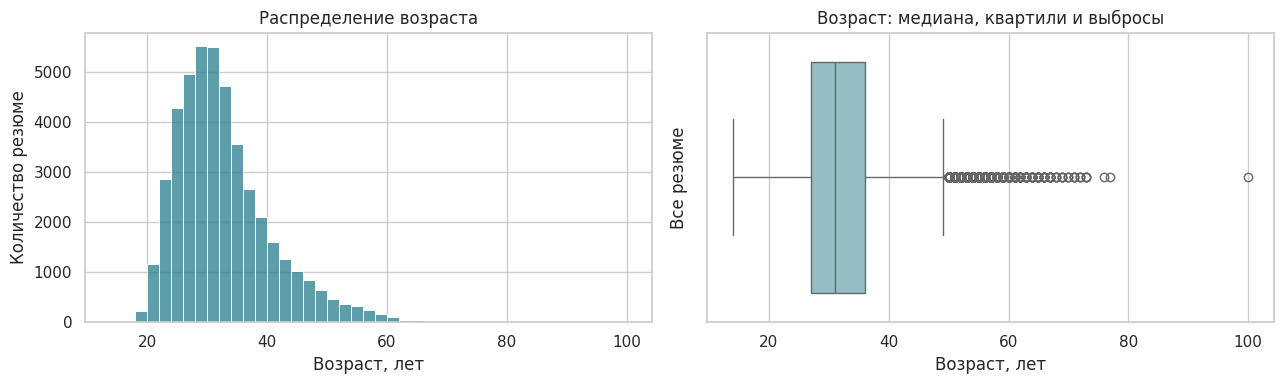

count    44744.000000
mean        32.196741
std          7.929800
min         14.000000
25%         27.000000
50%         31.000000
75%         36.000000
max        100.000000
Мода возраста: [30]
Доля от 20 до 40 лет, %: 85.4
Возраст до 18 и старше 75 лет:
Возраст
14      1
15      2
16      4
17     14
76      1
77      1
100     1


In [ ]:
sns.set_theme(style='whitegrid', font='DejaVu Sans')
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(hh_data['Возраст'], binwidth=2, ax=axes[0], color='#287d8e')
sns.boxplot(x=hh_data['Возраст'], ax=axes[1], color='#8bc4cb')
axes[0].set(title='Распределение возраста', xlabel='Возраст, лет', ylabel='Количество резюме')
axes[1].set(title='Возраст: медиана, квартили и выбросы', xlabel='Возраст, лет')
axes[1].set_ylabel('Все резюме')
plt.tight_layout()
plt.show()
print(hh_data['Возраст'].describe().to_string())
print('Мода возраста:', hh_data['Возраст'].mode().tolist())
print('Доля от 20 до 40 лет, %:', round(hh_data['Возраст'].between(20, 40).mean() * 100, 1))
print('Возраст до 18 и старше 75 лет:')
print(hh_data.loc[(hh_data['Возраст'] < 18) | (hh_data['Возраст'] > 75), 'Возраст'].value_counts().sort_index().to_string())

Модальный возраст — 30 лет, медиана — 31 год. Возраст меняется от 14 до 100 лет; половина резюме приходится на интервал 27–36 лет, а 85,4% — на 20–40 лет. Распределение имеет правый хвост.

Возраст 100 лет выглядит подозрительно и требует проверки. Редкие значения 14–17 и 76–77 лет также стоит проверить, но их редкость сама по себе ещё не доказывает ошибку: молодой или пожилой человек может искать работу.

2. Постройте распределение признака **"Опыт работы (месяц)"**. Опишите данное распределение, отвечая на следующие вопросы: чему равна мода распределения, каковы предельные значения признака, в каком примерном интервале находится опыт работы большинства соискателей? Есть ли аномалии для признака опыта работы, какие значения вы бы причислили к их числу?
*Совет: постройте гистограмму и коробчатую диаграмму рядом.*

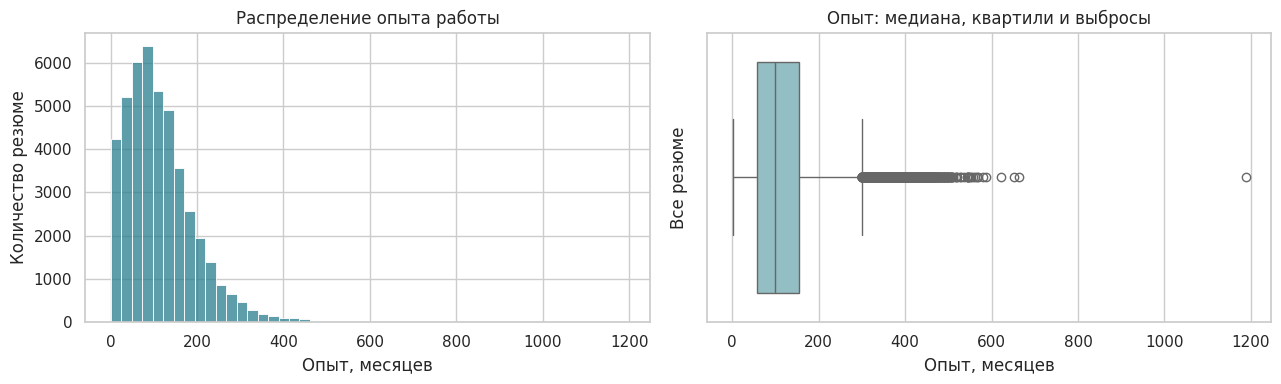

count    44574.000000
mean       114.418944
std         79.047861
min          1.000000
25%         57.000000
50%        100.000000
75%        154.000000
max       1188.000000
Мода опыта, месяцев: [81.0]
Доля от 24 до 180 месяцев, %: 74.0
Максимальный опыт в годах: 99.0


In [ ]:
experience = hh_data['Опыт работы (месяц)'].dropna()
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(experience, binwidth=24, ax=axes[0], color='#287d8e')
sns.boxplot(x=experience, ax=axes[1], color='#8bc4cb')
axes[0].set(title='Распределение опыта работы', xlabel='Опыт, месяцев', ylabel='Количество резюме')
axes[1].set(title='Опыт: медиана, квартили и выбросы', xlabel='Опыт, месяцев')
axes[1].set_ylabel('Все резюме')
plt.tight_layout()
plt.show()
print(experience.describe().to_string())
print('Мода опыта, месяцев:', experience.mode().tolist())
print('Доля от 24 до 180 месяцев, %:', round(experience.between(24, 180).mean() * 100, 1))
print('Максимальный опыт в годах:', experience.max() / 12)

Мода опыта — 81 месяц (6 лет 9 месяцев), медиана — 100 месяцев. Минимум равен 1 месяцу, максимум — 1188 месяцам (99 годам). Половина наблюдений находится между 57 и 154 месяцами, 74% — между 24 и 180 месяцами. Распределение скошено вправо.

Опыт 99 лет выглядит неправдоподобно. Большой опыт нужно сопоставлять с возрастом соискателя: значения, превышающие возраст, являются явной несогласованностью. Большой стаж сам по себе не служит достаточным основанием для удаления резюме.

3. Постройте распределение признака **"ЗП (руб)"**. Опишите данное распределение, отвечая на следующие вопросы: каковы предельные значения признака, в каком примерном интервале находится заработная плата большинства соискателей? Есть ли аномалии для признака возраста? Обратите внимание на гигантские размеры желаемой заработной платы.
*Совет: постройте гистограмму и коробчатую диаграмму рядом.*


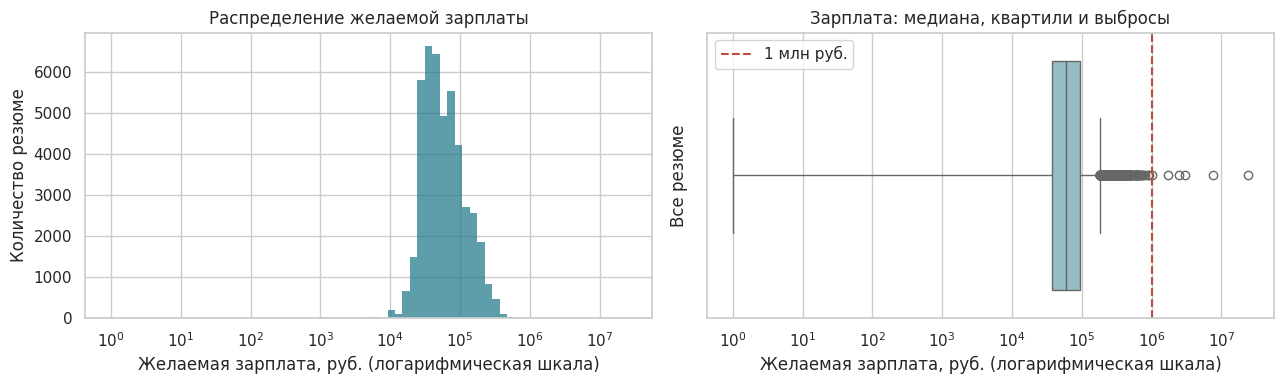

count    4.474400e+04
mean     7.653354e+04
std      1.359315e+05
min      1.000000e+00
25%      3.708220e+04
50%      5.901900e+04
75%      9.500000e+04
max      2.430488e+07
Мода зарплаты: [50000.0]
Зарплата выше 1 млн руб.: 5
Доля зарплат от 20 до 100 тыс. руб., %: 78.0


In [ ]:
salary = hh_data['ЗП (руб)']
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
# Логарифмическая ось позволяет показать и основную массу, и крупные выбросы.
sns.histplot(salary, bins=np.geomspace(salary.min(), salary.max(), 70),
             ax=axes[0], color='#287d8e')
sns.boxplot(x=salary, ax=axes[1], color='#8bc4cb')
for ax in axes:
    ax.set_xscale('log')
    ax.set_xlabel('Желаемая зарплата, руб. (логарифмическая шкала)')
axes[0].set(title='Распределение желаемой зарплаты', ylabel='Количество резюме')
axes[1].set_title('Зарплата: медиана, квартили и выбросы')
axes[1].axvline(1_000_000, color='#bc4b40', linestyle='--', label='1 млн руб.')
axes[1].legend()
axes[1].set_ylabel('Все резюме')
plt.tight_layout()
plt.show()
print(salary.describe().to_string())
print('Мода зарплаты:', salary.mode().tolist())
print('Зарплата выше 1 млн руб.:', salary.gt(1_000_000).sum())
print('Доля зарплат от 20 до 100 тыс. руб., %:', round(salary.between(20_000, 100_000).mean() * 100, 1))

Медиана желаемой зарплаты — 59 019 руб., мода — 50 000 руб. Половина значений находится в интервале примерно 37,1–95 тыс. руб., а 78% — от 20 до 100 тыс. руб. Распределение имеет выраженный правый хвост, поэтому среднее (около 76,5 тыс. руб.) превышает медиану.

Значения меняются от 1 руб. до 24,3 млн руб. Пять резюме содержат зарплату выше 1 млн руб. Чрезвычайно маленькие и большие суммы требуют проверки: возможны ошибки ввода, указания валюты или единиц. Логарифмическая шкала показывает весь диапазон без удаления этих наблюдений.

4. Постройте диаграмму, которая показывает зависимость **медианной** желаемой заработной платы (**"ЗП (руб)"**) от уровня образования (**"Образование"**). Используйте для диаграммы данные о резюме, где желаемая заработная плата меньше 1 млн рублей.
*Сделайте выводы по представленной диаграмме: для каких уровней образования наблюдаются наибольшие и наименьшие уровни желаемой заработной платы? Как вы считаете, важен ли признак уровня образования при прогнозировании заработной платы?*

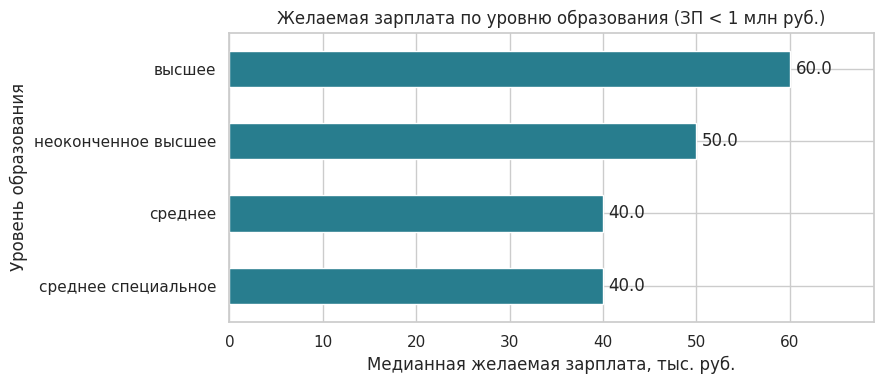

Образование
среднее специальное    40000.0
среднее                40000.0
неоконченное высшее    50000.0
высшее                 60000.0


In [ ]:
salary_below_million = hh_data.loc[hh_data['ЗП (руб)'] < 1_000_000].copy()
education_salary = salary_below_million.groupby('Образование')['ЗП (руб)'].median().sort_values()
fig, ax = plt.subplots(figsize=(9, 4))
(education_salary / 1000).plot.barh(ax=ax, color='#287d8e')
ax.set(title='Желаемая зарплата по уровню образования (ЗП < 1 млн руб.)',
       xlabel='Медианная желаемая зарплата, тыс. руб.', ylabel='Уровень образования')
ax.bar_label(ax.containers[0], fmt='%.1f', padding=4)
ax.set_xlim(0, education_salary.max() / 1000 * 1.15)
plt.tight_layout()
plt.show()
print(education_salary.to_string())

При зарплате ниже 1 млн руб. наибольшая медиана наблюдается у соискателей с высшим образованием — 60 тыс. руб. Далее следует неоконченное высшее — 50 тыс. руб. У среднего и среднего специального образования медианы одинаковы — 40 тыс. руб.

Образование связано с зарплатными ожиданиями и может быть полезным признаком для модели. Однако это описательная зависимость: на различия также могут влиять возраст, опыт, должность и город. График отражает желаемую, а не фактически выплачиваемую зарплату.

5. Постройте диаграмму, которая показывает распределение желаемой заработной платы (**"ЗП (руб)"**) в зависимости от города (**"Город"**). Используйте для диаграммы данные о резюме, где желая заработная плата меньше 1 млн рублей.
*Сделайте выводы по полученной диаграмме: как соотносятся медианные уровни желаемой заработной платы и их размах в городах? Как вы считаете, важен ли признак города при прогнозировании заработной платы?*

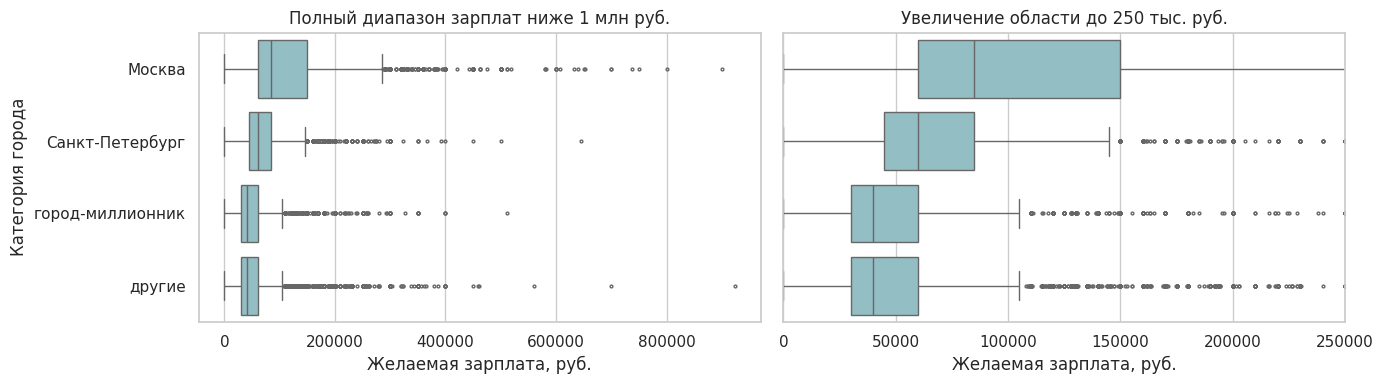

                  min   median       max
Город                                   
Москва            1.0  85000.0  900000.0
Санкт-Петербург   1.0  60000.0  645171.0
город-миллионник  1.0  40000.0  511681.6
другие            1.0  40000.0  923983.0
Самая высокая зарплата ниже 1 млн: другие


In [ ]:
city_order = ['Москва', 'Санкт-Петербург', 'город-миллионник', 'другие']
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax in axes:
    sns.boxplot(data=salary_below_million, x='ЗП (руб)', y='Город',
                order=city_order, color='#8bc4cb', fliersize=2, ax=ax)
    ax.set(xlabel='Желаемая зарплата, руб.', ylabel='Категория города')
axes[0].set_title('Полный диапазон зарплат ниже 1 млн руб.')
axes[1].set(title='Увеличение области до 250 тыс. руб.', xlim=(0, 250_000))
plt.tight_layout()
plt.show()
city_salary = salary_below_million.groupby('Город')['ЗП (руб)'].agg(['min', 'median', 'max'])
print(city_salary.round(2).to_string())
print('Самая высокая зарплата ниже 1 млн:', city_salary['max'].idxmax())

Наибольшая медиана желаемой зарплаты — в Москве (85 тыс. руб.), затем в Санкт-Петербурге (60 тыс. руб.). Для городов-миллионников и остальных городов медиана равна 40 тыс. руб. В Москве центральная часть распределения смещена к более высоким суммам и имеет больший разброс.

Максимум среди зарплат ниже 1 млн руб. отмечен в категории «другие» — 923 983 руб.; в Москве он равен 900 тыс. руб. Поэтому высокий единичный максимум не означает высокую зарплату типичного соискателя. Город полезен для прогнозирования, но его связь с ожиданиями следует рассматривать вместе с профессией и опытом.

6. Постройте **многоуровневую столбчатую диаграмму**, которая показывает зависимость медианной заработной платы (**"ЗП (руб)"**) от признаков **"Готовность к переезду"** и **"Готовность к командировкам"**. Проанализируйте график, сравнив уровень заработной платы в категориях.

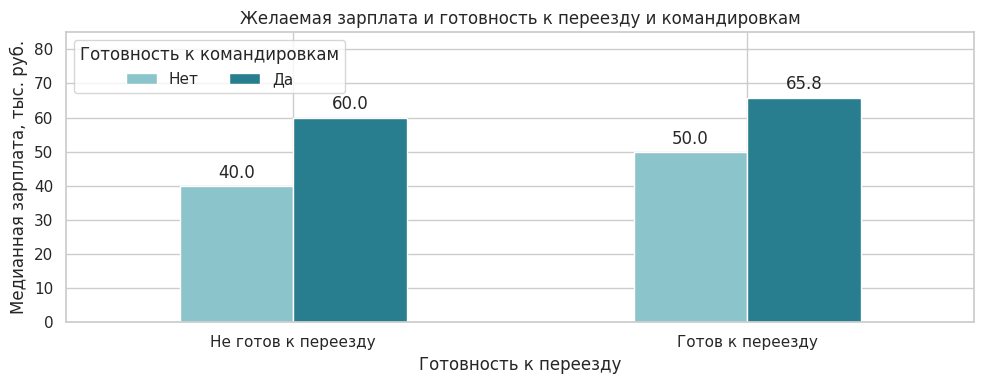

Готовность к командировкам    False      True 
Готовность к переезду                         
False                       40000.0  60000.000
True                        50000.0  65849.455


In [ ]:
mobility_salary = hh_data.pivot_table(
    index='Готовность к переезду', columns='Готовность к командировкам',
    values='ЗП (руб)', aggfunc='median')
plot_mobility = mobility_salary.rename(index={False: 'Не готов к переезду', True: 'Готов к переезду'},
                                       columns={False: 'Нет', True: 'Да'})
fig, ax = plt.subplots(figsize=(10, 4))
(plot_mobility / 1000).plot.bar(ax=ax, color=['#8bc4cb', '#287d8e'], rot=0)
ax.set(title='Желаемая зарплата и готовность к переезду и командировкам',
       xlabel='Готовность к переезду', ylabel='Медианная зарплата, тыс. руб.')
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f', padding=3)
ax.set_ylim(0, 85)
ax.legend(title='Готовность к командировкам', loc='upper left', ncol=2)
plt.tight_layout()
plt.show()
print(mobility_salary.to_string())

Самая высокая медиана — у соискателей, готовых и к переезду, и к командировкам: 65 849,455 руб. (около 66 тыс. руб.). Готовность только к командировкам соответствует медиане 60 тыс. руб., только к переезду — 50 тыс. руб., отсутствие обеих готовностей — 40 тыс. руб.

В этой выборке мобильность связана с более высокими зарплатными ожиданиями. Это не доказывает, что сама готовность к поездкам повышает зарплату: состав профессий, опыт и должности в группах могут различаться.

7. Постройте сводную таблицу, иллюстрирующую зависимость **медианной** желаемой заработной платы от возраста (**"Возраст"**) и образования (**"Образование"**). На полученной сводной таблице постройте **тепловую карту**. Проанализируйте тепловую карту, сравнив показатели внутри групп.

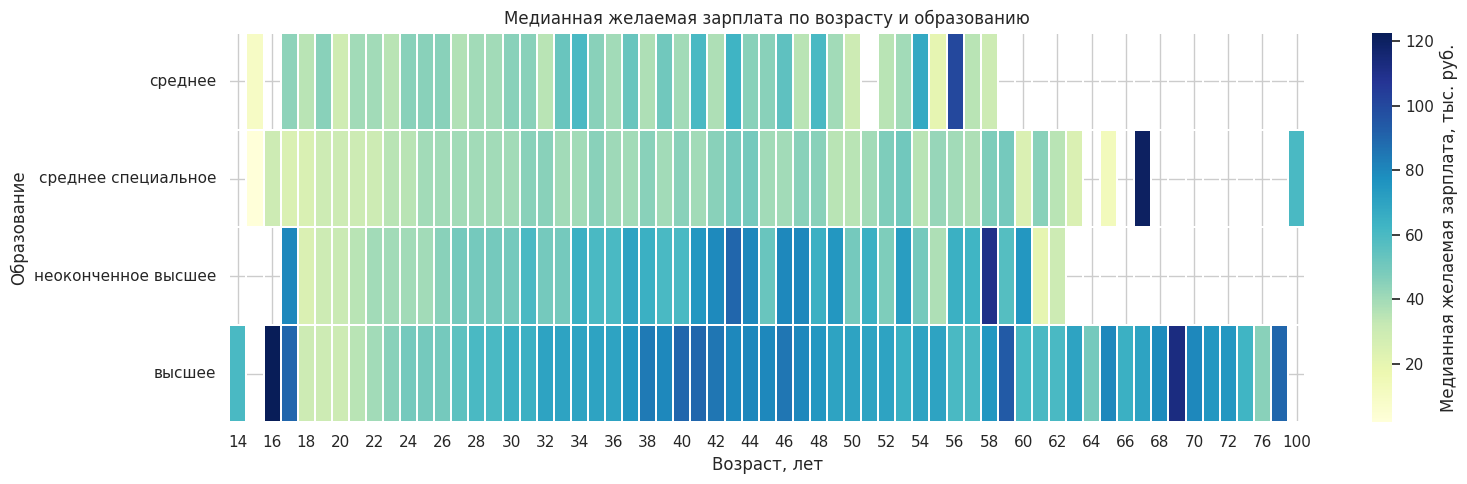

Медианные зарплаты в отдельных возрастах, тыс. руб.:
Возраст                20    25    30    35    40    45    50    55    60
Образование                                                              
среднее              29.0  45.0  45.0  45.0  40.0  45.0  30.0  20.0   NaN
среднее специальное  30.0  40.0  40.0  45.0  45.0  40.0  35.0  42.5  25.0
неоконченное высшее  31.0  40.0  50.0  60.0  60.0  52.5  50.0  37.5  75.0
высшее               30.0  50.0  65.0  70.0  90.0  80.0  70.0  70.0  60.8
Число резюме в возрастах от 60 лет по образованию:
Образование
высшее                 216
среднее специальное     10
неоконченное высшее      4


In [ ]:
education_order = ['среднее', 'среднее специальное', 'неоконченное высшее', 'высшее']
age_education_salary = hh_data.pivot_table(
    index='Образование', columns='Возраст', values='ЗП (руб)', aggfunc='median'
).reindex(education_order)
fig, ax = plt.subplots(figsize=(16, 5))
sns.heatmap(age_education_salary / 1000, cmap='YlGnBu', ax=ax,
            linewidths=0.2, xticklabels=2,
            cbar_kws={'label': 'Медианная желаемая зарплата, тыс. руб.'})
ax.set(title='Медианная желаемая зарплата по возрасту и образованию',
       xlabel='Возраст, лет', ylabel='Образование')
ax.tick_params(axis='y', rotation=0)
plt.tight_layout()
plt.show()
print('Медианные зарплаты в отдельных возрастах, тыс. руб.:')
print((age_education_salary.reindex(columns=[20, 25, 30, 35, 40, 45, 50, 55, 60]) / 1000).round(1).to_string())
print('Число резюме в возрастах от 60 лет по образованию:')
print(hh_data.loc[hh_data['Возраст'] >= 60, 'Образование'].value_counts().to_string())

Для высшего образования увеличение медианных зарплатных ожиданий с возрастом выражено сильнее: в 20 лет медиана около 30 тыс. руб., в 30 — 65 тыс., в 40 — 90 тыс. Для неоконченного высшего соответствующие значения составляют примерно 31, 50 и 60 тыс. руб. У среднего и среднего специального образования рост слабее.

В старших возрастах картина неоднородна, а отдельные клетки основаны на малом числе резюме: например, среди соискателей от 60 лет всего четыре резюме с неоконченным высшим образованием. Пропуски на карте означают отсутствие наблюдений, а не нулевую зарплату. Срез разных людей по возрасту не позволяет измерить реальный карьерный рост одного человека; здесь сравниваются ожидания разных возрастных групп.

8. Постройте **диаграмму рассеяния**, показывающую зависимость опыта работы (**"Опыт работы (месяц)"**) от возраста (**"Возраст"**). Опыт работы переведите из месяцев в года, чтобы признаки были в едином масштабе. Постройте на графике дополнительно прямую, проходящую через точки (0, 0) и (100, 100). Данная прямая соответствует значениям, когда опыт работы равен возрасту человека. Точки, лежащие на этой прямой и выше нее - аномалии в наших данных (опыт работы больше либо равен возрасту соискателя)

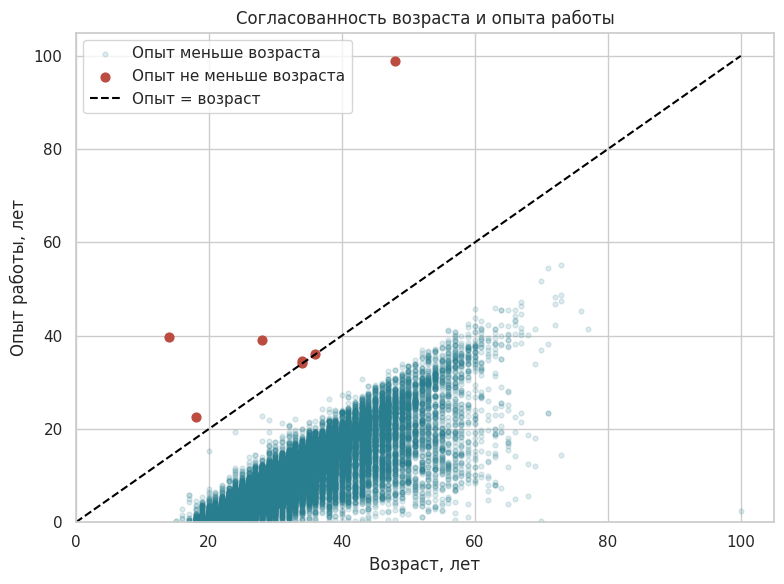

Строго выше прямой: 7
На прямой и выше: 7
       Возраст  Опыт работы (месяц)
4535        18                271.0
19351       28                470.0
19872       34                416.0
26477       34                411.0
29098       14                477.0
40015       48               1188.0
43451       36                434.0


In [ ]:
experience_years = hh_data['Опыт работы (месяц)'] / 12
above_age = experience_years > hh_data['Возраст']
on_or_above_age = experience_years >= hh_data['Возраст']
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(hh_data.loc[~on_or_above_age, 'Возраст'], experience_years[~on_or_above_age],
           s=12, alpha=0.15, color='#287d8e', label='Опыт меньше возраста')
ax.scatter(hh_data.loc[on_or_above_age, 'Возраст'], experience_years[on_or_above_age],
           s=40, color='#bc4b40', label='Опыт не меньше возраста')
ax.plot([0, 100], [0, 100], linestyle='--', color='black', label='Опыт = возраст')
ax.set(title='Согласованность возраста и опыта работы',
       xlabel='Возраст, лет', ylabel='Опыт работы, лет', xlim=(0, 105), ylim=(0, 105))
ax.legend()
plt.tight_layout()
plt.show()
print('Строго выше прямой:', above_age.sum())
print('На прямой и выше:', on_or_above_age.sum())
print(hh_data.loc[on_or_above_age, ['Возраст', 'Опыт работы (месяц)']].to_string())

В основном опыт увеличивается с возрастом и остаётся заметно меньше него, что согласуется с началом трудовой деятельности после детства и учёбы. Строго выше прямой «опыт = возраст» находятся семь резюме: их общий стаж превышает возраст соискателя и является ошибкой либо требует уточнения.

Такие наблюдения удалим на этапе очистки. Даже некоторые точки ниже прямой могут быть подозрительными (слишком раннее начало работы), однако без дополнительной информации расширять правило удаления не будем.

**Дополнительные баллы**

Для получения 2 дополнительных баллов по разведывательному анализу постройте еще два любых содержательных графика или диаграммы, которые помогут проиллюстрировать влияние признаков/взаимосвязь между признаками/распределения признаков. Приведите выводы по ним. Желательно, чтобы в анализе участвовали признаки, которые мы создавали ранее в разделе "Преобразование данных".


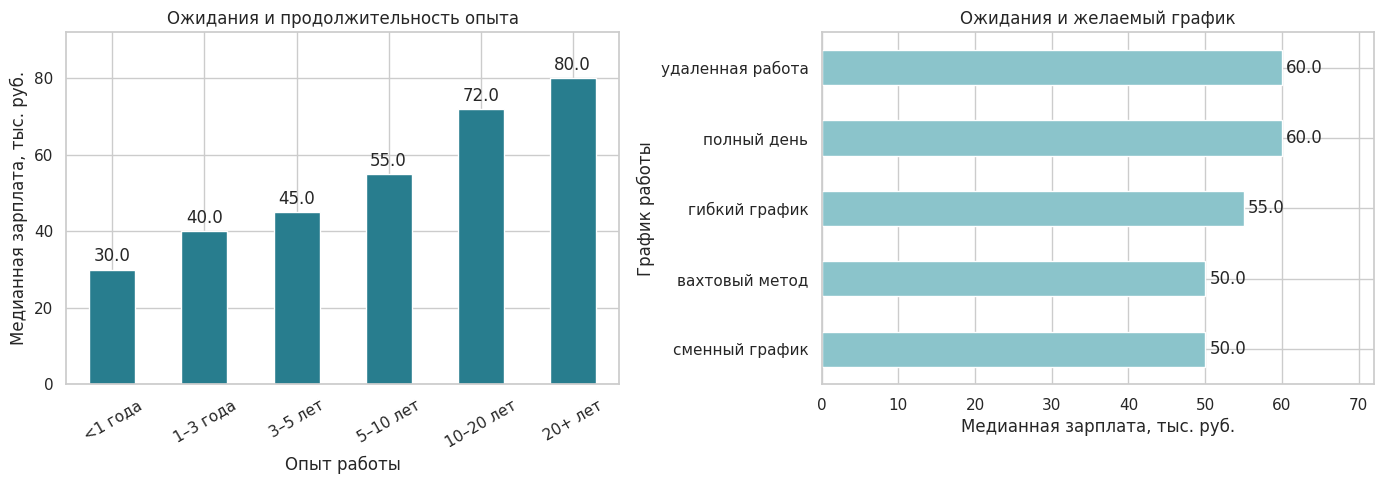

Группы опыта:
              count   median
Группа опыта                
<1 года        1484  30000.0
1–3 года       4869  40000.0
3–5 лет        5527  45000.0
5–10 лет      14721  55000.0
10–20 лет     14784  72000.0
20+ лет        3183  80000.0
Предпочитаемый график (группы могут пересекаться):
                    count   median
сменный график    12724.0  50000.0
вахтовый метод     3083.0  50000.0
гибкий график     15581.0  55000.0
полный день       41710.0  60000.0
удаленная работа  15018.0  60000.0


In [ ]:
# Два дополнительных сравнения на данных с зарплатой ниже 1 млн руб.
extra = salary_below_million.copy()
extra['Группа опыта'] = pd.cut(extra['Опыт работы (месяц)'],
    bins=[0, 12, 36, 60, 120, 240, np.inf], right=False,
    labels=['<1 года', '1–3 года', '3–5 лет', '5–10 лет', '10–20 лет', '20+ лет'])
experience_salary = extra.groupby('Группа опыта', observed=True)['ЗП (руб)'].agg(['count', 'median'])
schedule_salary = pd.DataFrame({
    category: {'count': int(extra[category].sum()),
               'median': extra.loc[extra[category], 'ЗП (руб)'].median()}
    for category in schedule_types
}).T.sort_values('median')
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
(experience_salary['median'] / 1000).plot.bar(ax=axes[0], color='#287d8e', rot=30)
axes[0].set(title='Ожидания и продолжительность опыта',
            xlabel='Опыт работы', ylabel='Медианная зарплата, тыс. руб.')
(schedule_salary['median'] / 1000).plot.barh(ax=axes[1], color='#8bc4cb')
axes[1].set(title='Ожидания и желаемый график',
            xlabel='Медианная зарплата, тыс. руб.', ylabel='График работы')
for ax in axes:
    ax.bar_label(ax.containers[0], fmt='%.1f', padding=3)
axes[0].set_ylim(0, experience_salary['median'].max() / 1000 * 1.15)
axes[1].set_xlim(0, schedule_salary['median'].max() / 1000 * 1.2)
plt.tight_layout()
plt.show()
print('Группы опыта:')
print(experience_salary.to_string())
print('Предпочитаемый график (группы могут пересекаться):')
print(schedule_salary.to_string())

Первый график показывает последовательный рост медианы зарплатных ожиданий с опытом: от 30 тыс. руб. при опыте менее года до 55 тыс. при 5–10 годах, 72 тыс. при 10–20 годах и 80 тыс. при опыте от 20 лет. Это подтверждает полезность опыта как признака, хотя возраст, специализация и должность могут объяснять часть различий.

Второй график показывает медианы 60 тыс. руб. для полного дня и удалённой работы, 55 тыс. для гибкого графика и 50 тыс. для сменного графика и вахтового метода. Один соискатель мог выбрать несколько графиков, поэтому группы пересекаются: их размеры нельзя суммировать, а различия нельзя считать эффектом самого графика. Оба графика построены на резюме с зарплатой ниже 1 млн руб.; пропуски опыта не включены в его группировку.

# Очистка данных

1. Начнем с дубликатов в наших данных. Найдите **полные дубликаты** в таблице с резюме и удалите их.

In [ ]:
# Исходную преобразованную таблицу сохраняем для повторного анализа.
hh_clean = hh_data.copy()
duplicates_count = int(hh_clean.duplicated().sum())
print('Полных дубликатов:', duplicates_count)
hh_clean = hh_clean.drop_duplicates().copy()
print('После удаления дубликатов:', hh_clean.shape)

Полных дубликатов: 161
После удаления дубликатов: (44583, 23)


2. Займемся пропусками. Выведите информацию **о числе пропусков** в столбцах.

In [ ]:
missing_counts = hh_clean.isna().sum()
print(missing_counts.to_string())
print('Пропусков опыта после удаления дубликатов:', missing_counts['Опыт работы (месяц)'])

Ищет работу на должность:            0
Последнее/нынешнее место работы      1
Последняя/нынешняя должность         2
Обновление резюме                    0
Авто                                 0
Образование                          0
Пол                                  0
Возраст                              0
Опыт работы (месяц)                168
Город                                0
Готовность к переезду                0
Готовность к командировкам           0
полная занятость                     0
частичная занятость                  0
проектная работа                     0
волонтерство                         0
стажировка                           0
полный день                          0
сменный график                       0
гибкий график                        0
удаленная работа                     0
вахтовый метод                       0
ЗП (руб)                             0
Пропусков опыта после удаления дубликатов: 168


3. Итак, у нас есть пропуски в 3ех столбцах: **"Опыт работы (месяц)"**, **"Последнее/нынешнее место работы"**, **"Последняя/нынешняя должность"**. Поступим следующим образом: удалите строки, где есть пропуск в столбцах с местом работы и должностью. Пропуски в столбце с опытом работы заполните **медианным** значением.

In [ ]:
rows_before_missing = len(hh_clean)
hh_clean = hh_clean.dropna(subset=['Последнее/нынешнее место работы',
                                  'Последняя/нынешняя должность']).copy()
experience_median = hh_clean['Опыт работы (месяц)'].median()
hh_clean['Опыт работы (месяц)'] = hh_clean['Опыт работы (месяц)'].fillna(experience_median)
print('Удалено строк с пропусками места работы/должности:', rows_before_missing - len(hh_clean))
print('Медиана для заполнения опыта:', experience_median)
print('Средний опыт после заполнения:', hh_clean['Опыт работы (месяц)'].mean())
print('Округлённый ответ:', round(hh_clean['Опыт работы (месяц)'].mean()))
print('Оставшихся пропусков:', int(hh_clean.isna().sum().sum()))

Удалено строк с пропусками места работы/должности: 2
Медиана для заполнения опыта: 100.0
Средний опыт после заполнения: 114.35777573405711
Округлённый ответ: 114
Оставшихся пропусков: 0


4. Мы добрались до ликвидации выбросов. Сначала очистим данные вручную. Удалите резюме, в которых указана заработная плата либо выше 1 млн. рублей, либо ниже 1 тыс. рублей.

In [ ]:
salary_outliers = (hh_clean['ЗП (руб)'] > 1_000_000) | (hh_clean['ЗП (руб)'] < 1_000)
print('Выбросов по зарплате:', int(salary_outliers.sum()))
hh_clean = hh_clean.loc[~salary_outliers].copy()
print('Осталось строк:', len(hh_clean))

Выбросов по зарплате: 89
Осталось строк: 44492


5. В процессе разведывательного анализа мы обнаружили резюме, в которых **опыт работы в годах превышал возраст соискателя**. Найдите такие резюме и удалите их из данных


In [ ]:
experience_outliers = hh_clean['Опыт работы (месяц)'] / 12 > hh_clean['Возраст']
print('Опыт превышает возраст, резюме:', int(experience_outliers.sum()))
print(hh_clean.loc[experience_outliers, ['Возраст', 'Опыт работы (месяц)']].to_string())
hh_clean = hh_clean.loc[~experience_outliers].copy()
print('Осталось строк:', len(hh_clean))

Опыт превышает возраст, резюме: 7
       Возраст  Опыт работы (месяц)
4535        18                271.0
19351       28                470.0
19872       34                416.0
26477       34                411.0
29098       14                477.0
40015       48               1188.0
43451       36                434.0
Осталось строк: 44485


6. В результате анализа мы обнаружили потенциальные выбросы в признаке **"Возраст"**. Это оказались резюме людей чересчур преклонного возраста для поиска работы. Попробуйте построить распределение признака в **логарифмическом масштабе**. Добавьте к графику линии, отображающие **среднее и границы интервала метода трех сигм**. Напомним, сделать это можно с помощью метода axvline. Например, для построение линии среднего будет иметь вид:

`histplot.axvline(log_age.mean(), color='k', lw=2)`

В какую сторону асимметрично логарифмическое распределение? Напишите об этом в комментарии к графику.
Найдите выбросы с помощью метода z-отклонения и удалите их из данных, используйте логарифмический масштаб. Давайте сделаем послабление на **1 сигму** (возьмите 4 сигмы) в **правую сторону**.

Выведите таблицу с полученными выбросами и оцените, с каким возрастом соискатели попадают под категорию выбросов?

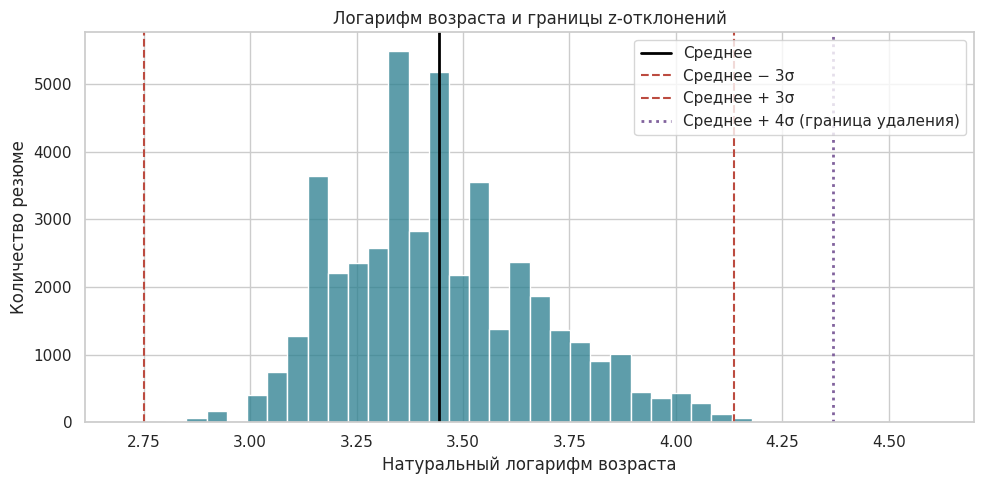

Асимметрия логарифма возраста: 0.452
Границы в годах: 15.66 78.88
Выбросов возраста: 3


,Возраст,Опыт работы (месяц),Образование,ЗП (руб)
31137,15,2.0,среднее,10000.0
32950,15,3.0,среднее специальное,2000.0
33654,100,30.0,среднее специальное,60000.0


Итоговый размер очищенной таблицы: (44482, 23)
Удалено строк всего: 262
Сохранено исходных строк, %: 99.41
Проверки пропусков, дубликатов, зарплаты и опыта пройдены.


In [ ]:
log_age = np.log(hh_clean['Возраст'])
log_mean, log_std = log_age.mean(), log_age.std()
lower = log_mean - 3 * log_std
upper_three = log_mean + 3 * log_std
upper = log_mean + 4 * log_std

fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(log_age, bins=40, ax=ax, color='#287d8e')
ax.axvline(log_mean, color='black', linewidth=2, label='Среднее')
ax.axvline(lower, color='#bc4b40', linestyle='--', label='Среднее − 3σ')
ax.axvline(upper_three, color='#bc4b40', linestyle='--', label='Среднее + 3σ')
ax.axvline(upper, color='#81629d', linestyle=':', linewidth=2, label='Среднее + 4σ (граница удаления)')
ax.set(title='Логарифм возраста и границы z-отклонений',
       xlabel='Натуральный логарифм возраста', ylabel='Количество резюме')
ax.legend()
plt.tight_layout()
plt.show()

age_outliers = (log_age < lower) | (log_age > upper)
print('Асимметрия логарифма возраста:', round(log_age.skew(), 3))
print('Границы в годах:', round(np.exp(lower), 2), round(np.exp(upper), 2))
print('Выбросов возраста:', int(age_outliers.sum()))
display(hh_clean.loc[age_outliers, ['Возраст', 'Опыт работы (месяц)', 'Образование', 'ЗП (руб)']])
hh_clean = hh_clean.loc[~age_outliers].copy()

assert not hh_clean.isna().any().any()
assert not hh_clean.duplicated().any()
assert hh_clean['ЗП (руб)'].between(1_000, 1_000_000).all()
assert (hh_clean['Опыт работы (месяц)'] / 12 <= hh_clean['Возраст']).all()
print('Итоговый размер очищенной таблицы:', hh_clean.shape)
print('Удалено строк всего:', len(hh_data) - len(hh_clean))
print('Сохранено исходных строк, %:', round(len(hh_clean) / len(hh_data) * 100, 2))
print('Проверки пропусков, дубликатов, зарплаты и опыта пройдены.')

Логарифмическое распределение возраста имеет небольшую правостороннюю асимметрию: коэффициент равен 0,452. По заданному правилу нижняя граница равна среднему минус 3σ, верхняя — среднему плюс 4σ. В исходных единицах это примерно 15,66–78,88 года. Найдены три выброса: два резюме с возрастом 15 лет и одно — 100 лет. Они удалены согласно условию проекта. Статистический критерий сам по себе не доказывает ошибочность всех таких записей.

Итог очистки: удалены 161 дубликат, 2 строки с пропусками места работы/должности, 89 выбросов зарплаты, 7 строк с опытом выше возраста и 3 выброса возраста. Пропуски опыта заполнены медианой 100 месяцев. Всего исключены 262 строки, сохранено 99,41% исходных резюме.

Очищенная таблица **hh_clean** содержит **44 482 строки и 23 признака**. Проверки отсутствия пропусков и полных дубликатов, допустимого диапазона зарплаты и согласованности опыта с возрастом выполнены успешно. Таблица **hh_data** сохранена для воспроизводимости разведывательного анализа; **hh_raw** — исходная версия до преобразований.